Sample Rate: 44100
Duration: 244.1022902494331 seconds


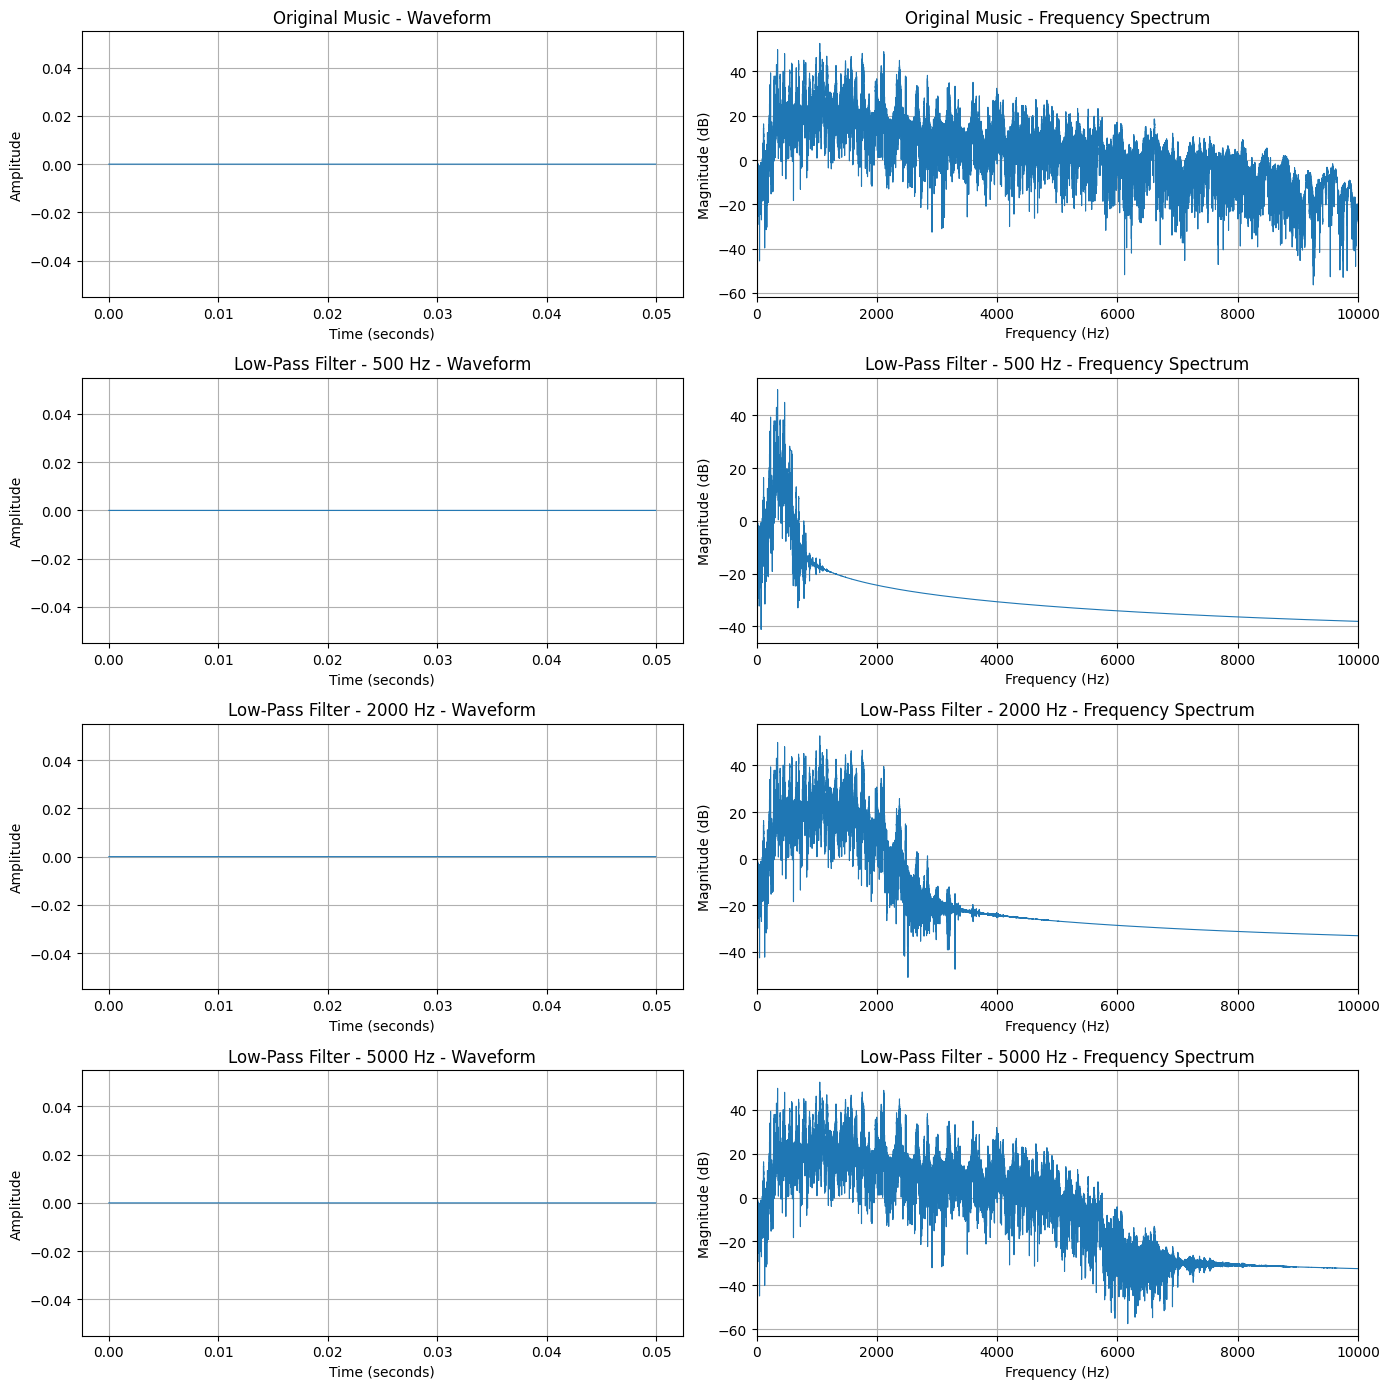

All filtered audio files saved successfully.


In [17]:
import librosa
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
from scipy.signal import butter, sosfiltfilt

filename = "Todh___Prince_Narula___Munawar__Official_Video____Jaymeet___Rony_Ajnali___Gill_Machhrai(128k).mp3"

y, sr = librosa.load(filename, sr=None)

print("Sample Rate:", sr)
print("Duration:", len(y) / sr, "seconds")

def lowpass_filter(data, cutoff, fs, order=6):
    sos = butter(order, cutoff, btype="lowpass", fs=fs, output="sos")
    return sosfiltfilt(sos, data)

cutoffs = [500, 2000, 5000]
signals = [("Original Music", y)]

for cutoff in cutoffs:
    filtered = lowpass_filter(y, cutoff, sr)
    sf.write(f"lowpass_{cutoff}Hz.wav", filtered, sr)
    signals.append((f"Low-Pass Filter - {cutoff} Hz", filtered))

samples = min(sr // 20, len(y))
time = np.arange(samples) / sr

fig, axes = plt.subplots(4, 2, figsize=(14, 14))

for i, (title, signal) in enumerate(signals):
    segment = signal[:samples]

    axes[i, 0].plot(time, segment, linewidth=0.8)
    axes[i, 0].set_title(title + " - Waveform")
    axes[i, 0].set_xlabel("Time (seconds)")
    axes[i, 0].set_ylabel("Amplitude")
    axes[i, 0].grid(True)

    spectrum = np.abs(np.fft.rfft(signal[:min(len(signal), sr * 5)]))
    frequencies = np.fft.rfftfreq(
        min(len(signal), sr * 5), d=1 / sr
    )

    spectrum_db = 20 * np.log10(spectrum + 1e-10)

    axes[i, 1].plot(frequencies, spectrum_db, linewidth=0.8)
    axes[i, 1].set_title(title + " - Frequency Spectrum")
    axes[i, 1].set_xlabel("Frequency (Hz)")
    axes[i, 1].set_ylabel("Magnitude (dB)")
    axes[i, 1].set_xlim(0, 10000)
    axes[i, 1].grid(True)

plt.tight_layout()
plt.show()

print("All filtered audio files saved successfully.")

Sample rate: 44100, Duration: 244.10 seconds


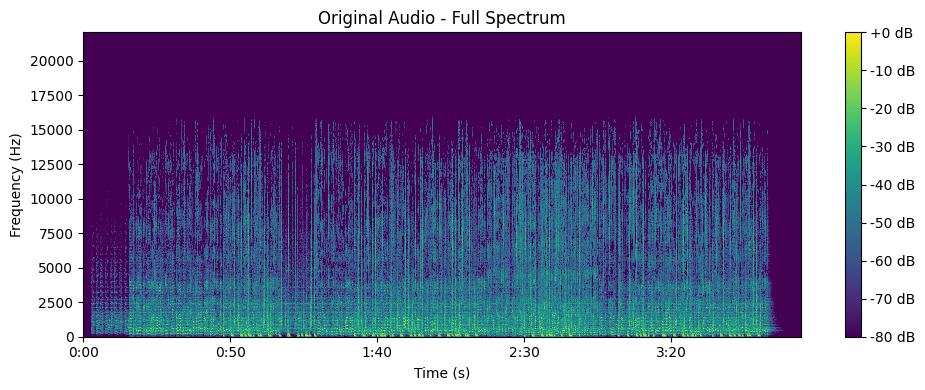

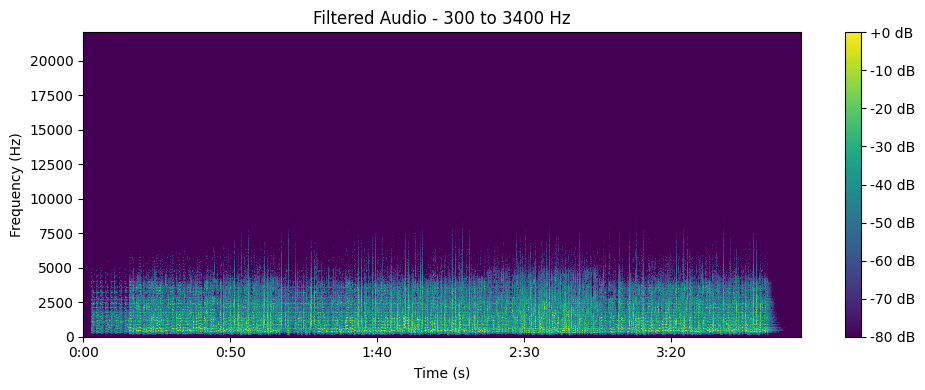

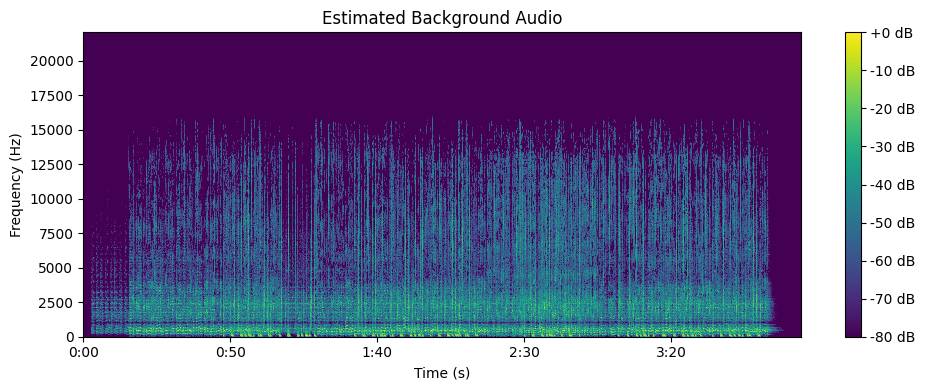

Filtered audio files saved successfully.


In [3]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
from scipy.signal import butter, lfilter

filename = '/content/Todh___Prince_Narula___Munawar__Official_Video____Jaymeet___Rony_Ajnali___Gill_Machhrai(128k).mp3'

y, sr = librosa.load(filename, sr=None)

print(f"Sample rate: {sr}, Duration: {len(y)/sr:.2f} seconds")

def butter_bandpass(lowcut, highcut, fs, order=6):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    return b, a

def bandpass_filter(data, lowcut, highcut, fs, order=6):
    b, a = butter_bandpass(lowcut, highcut, fs, order)
    return lfilter(b, a, data)

vocal_band = bandpass_filter(y, 300, 3400, sr)
background_band = y - vocal_band

def plot_spectrogram(signal, sr, title):
    D = librosa.amplitude_to_db(
        np.abs(librosa.stft(signal)),
        ref=np.max
    )

    plt.figure(figsize=(10, 4))
    librosa.display.specshow(
        D,
        sr=sr,
        x_axis='time',
        y_axis='hz',
        cmap='viridis'
    )
    plt.colorbar(format='%+2.0f dB')
    plt.title(title)
    plt.xlabel('Time (s)')
    plt.ylabel('Frequency (Hz)')
    plt.tight_layout()
    plt.show()

plot_spectrogram(y, sr, 'Original Audio - Full Spectrum')
plot_spectrogram(vocal_band, sr, 'Filtered Audio - 300 to 3400 Hz')
plot_spectrogram(background_band, sr, 'Estimated Background Audio')

sf.write('/content/filtered_vocals.wav', vocal_band, sr)
sf.write('/content/estimated_background.wav', background_band, sr)

print("Filtered audio files saved successfully.")